# Academic Data Explorer

Now that all of our data is in either bibtex files or json files we can sort do some exploritory data anaysis on our anademic work.  This fill does some basic analysis.  Note that ```bibtexparser``` is required to read the bibtex files.  

```pip install bibtexparser```

In [15]:
import cvpy
data = cvpy.load_all_data()

Entry type thesis not standard. Not considered.
Entry type thesis not standard. Not considered.
Entry type online not standard. Not considered.


In [16]:
counts = {k: len(v) for k, v in data.items()}
counts

{'roles': 10,
 'service': 14,
 'engineering': 5,
 'presentations': 56,
 'projects': 2,
 'courses': 15,
 'grants': 9,
 'graduate_committees': 13,
 'honors_awards': 16,
 'scholarly_outputs': 83,
 'publications': 80,
 'graduate_students': 13}

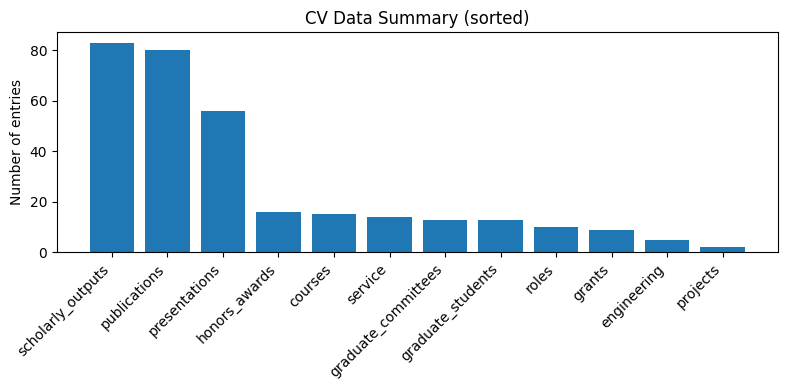

In [17]:
import matplotlib.pylab as plt 
import pandas as pd

df = pd.DataFrame(list(counts.items()), columns=["type", "count"])
df = df.sort_values("count", ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(df["type"], df["count"])

plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of entries")
plt.title("CV Data Summary (sorted)")

plt.tight_layout()
plt.show()

<Axes: xlabel='year'>

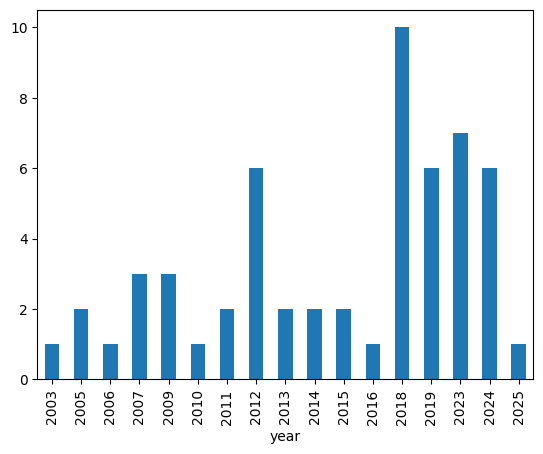

In [22]:
import pandas as pd

talks = pd.DataFrame(data["presentations"])
talks["year"] = talks["date"].str.extract(r"(\d{4})").astype(int)

talks.groupby("year").size().plot(kind="bar")

<Axes: ylabel='count'>

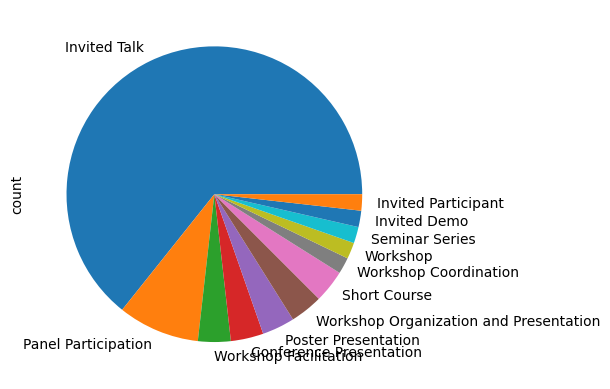

In [23]:
talks["activity_type"].value_counts().plot.pie()

In [30]:
import re

def extract_year(x):
    if x is None:
        return None

    match = re.search(r"\b(19|20)\d{2}\b", str(x))
    return int(match.group(0)) if match else None

<Axes: title={'center': 'Publications per Year'}, xlabel='year'>

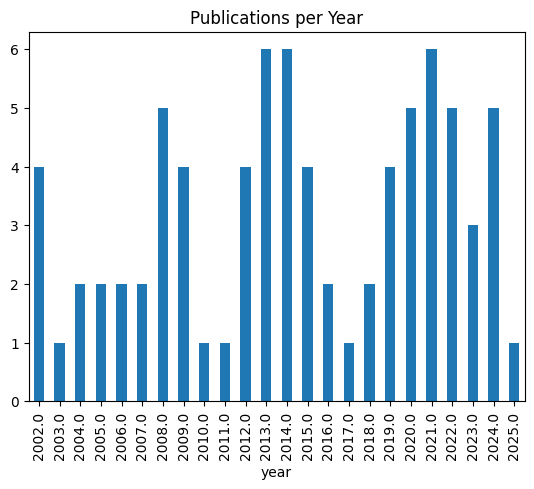

In [31]:
pubs = pd.DataFrame(data["publications"])
pubs["year"] = pubs["date"].apply(extract_year)
pubs = pubs[pubs["year"].notna()]
pubs.groupby("year").size().plot(kind="bar", title="Publications per Year")

In [32]:
all_items = []

for name, dataset in data.items():
    for item in dataset:
        item["_source"] = name
        all_items.append(item)

df = pd.DataFrame(all_items)

df["year"] = df.apply(
    lambda x: extract_year(x.get("date") or x.get("year")),
    axis=1
)

In [33]:
df.groupby(["_source", "year"]).size()

_source        year  
presentations  2003.0     1
               2005.0     2
               2006.0     1
               2007.0     3
               2009.0     3
               2010.0     1
               2011.0     2
               2012.0     6
               2013.0     2
               2014.0     2
               2015.0     2
               2016.0     1
               2018.0    10
               2019.0     6
               2023.0     7
               2024.0     6
               2025.0     1
publications   2002.0     4
               2003.0     1
               2004.0     2
               2005.0     2
               2006.0     2
               2007.0     2
               2008.0     5
               2009.0     4
               2010.0     1
               2011.0     1
               2012.0     4
               2013.0     6
               2014.0     6
               2015.0     4
               2016.0     2
               2017.0     1
               2018.0     2
               2019.0     